<a href="https://colab.research.google.com/github/Heimrath/Tarefa-Boosting-Baggin/blob/main/Atividade_IA_ML_Ensemble_Luan_Matheus_airports.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="right">
<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" width="150">
</div>

# Ciências da Computação: Inteligência Artificial
## Machine Learning: Ensemble Learning com Bagging, Boosting e Stacking

**Atividade de laboratório, PUC-SP**

**Integrantes:** Luan Bonasorte Capella e Matheus Heimrath Barbosa.

**Objetivo:** implementar modelos de *Bagging*, *Boosting* e *Stacking* com Scikit-Learn utilizando o conjunto de dados `airports` do pacote `vega_datasets`, treinar os modelos e comparar o desempenho de cada um em dados não utilizados no treinamento.

## 1. Introdução

Métodos de *Ensemble Learning* combinam as previsões de vários estimadores para obter um modelo mais robusto e com maior capacidade de generalização do que um único estimador. Este laboratório explora as três principais famílias de ensembles disponíveis no Scikit-Learn.

No **Bagging** (*Bootstrap Aggregating*), os estimadores são treinados de forma independente, cada um com uma amostra obtida por amostragem com reposição, e as previsões são combinadas por votação. O foco é reduzir a variância. No **Boosting**, os estimadores são treinados de forma sequencial, e cada novo estimador tenta corrigir os erros cometidos pelos anteriores. O foco é reduzir o viés. No **Stacking**, estimadores de naturezas diferentes são treinados sobre os mesmos dados e um classificador final, chamado de meta-aprendiz, aprende a combinar as previsões deles da melhor maneira.

Para contextualizar os resultados, os três ensembles serão comparados entre si e também com uma única árvore de decisão, usada como modelo de referência.

Referências principais: documentação do Scikit-Learn sobre [Ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html), [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html), [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) e [StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html), além do repositório dos [Vega datasets](https://github.com/vega/vega-datasets).

## 2. Bibliotecas

O pacote `vega_datasets` fornece conjuntos de dados utilizados em exemplos e visualizações. Caso ainda não esteja instalado no ambiente, execute a célula abaixo.

In [1]:
%pip install -q vega_datasets scikit-learn pandas matplotlib seaborn

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from vega_datasets import data

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
    RandomForestClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

print("Bibliotecas importadas com sucesso.")

Bibliotecas importadas com sucesso.


## 3. Carregamento e exploração dos dados

Será utilizado o conjunto **Airports**, disponibilizado pelo `vega_datasets`. Ele contém um registro para cada aeroporto dos Estados Unidos e territórios, com o código IATA, o nome, a cidade, o estado, o país, a latitude e a longitude.

O problema será tratado como uma tarefa de **classificação multiclasse**. Como o conjunto não possui uma categoria pronta para ser prevista, a variável-alvo será construída a partir da coluna `state`, agrupando os estados nas quatro regiões do Censo dos Estados Unidos (Northeast, Midwest, South e West) e em um grupo adicional para os territórios. Os modelos tentarão prever essa região usando apenas a localização geográfica do aeroporto, isto é, sua latitude e sua longitude.

In [3]:
# Carregamento do conjunto de dados do Vega
df = data.airports()

print("Dimensões do conjunto:", df.shape)
display(df.head())

print("\nTipos e valores ausentes:")
df.info()

print("\nValores ausentes por coluna:")
display(df.isna().sum().rename("ausentes").to_frame())

Dimensões do conjunto: (3376, 7)


,iata,name,city,state,country,latitude,longitude
0,00M,Thigpen,Bay Springs,MS,USA,31.953765,-89.234505
1,00R,Livingston Municipal,Livingston,TX,USA,30.685861,-95.017928
2,00V,Meadow Lake,Colorado Springs,CO,USA,38.945749,-104.569893
3,01G,Perry-Warsaw,Perry,NY,USA,42.741347,-78.052081
4,01J,Hilliard Airpark,Hilliard,FL,USA,30.688012,-81.905944



Tipos e valores ausentes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iata       3376 non-null   object 
 1   name       3376 non-null   object 
 2   city       3364 non-null   object 
 3   state      3364 non-null   object 
 4   country    3376 non-null   object 
 5   latitude   3376 non-null   float64
 6   longitude  3376 non-null   float64
dtypes: float64(2), object(5)
memory usage: 184.8+ KB

Valores ausentes por coluna:


,ausentes
iata,0
name,0
city,12
state,12
country,0
latitude,0
longitude,0


In [4]:
# Estatísticas descritivas das variáveis numéricas
display(df[["latitude", "longitude"]].describe())

# Quantidade de aeroportos por estado (10 mais frequentes)
display(df["state"].value_counts().head(10).rename_axis("state").to_frame("quantidade"))

,latitude,longitude
count,3376.000000,3376.000000
mean,40.036524,-98.621205
std,8.329559,22.869458
min,7.367222,-176.646031
25%,34.688427,-108.761121
50%,39.434449,-93.599425
75%,43.372612,-84.137519
max,71.285448,145.621384


,quantidade
state,
AK,263
TX,209
CA,205
OK,102
OH,100
FL,100
GA,97
NY,97
MI,94


## 4. Preparação dos dados

A variável-alvo `regiao` é obtida a partir da coluna `state` por meio de um dicionário que associa cada sigla de estado à sua região. As variáveis preditoras são `latitude` e `longitude`. A coluna `state` é usada apenas para construir o alvo e não entra como preditora, o que evitaria vazamento de informação.

Registros sem latitude, longitude ou região conhecida são removidos, pois imputar coordenadas geográficas por uma medida como a mediana não faria sentido. Também são descartadas as classes com pouquíssimos exemplos, que inviabilizariam a divisão estratificada.

A separação entre treino e teste é feita uma única vez, antes do ajuste de qualquer modelo, de modo que todos sejam treinados e avaliados exatamente com os mesmos dados e a comparação seja justa.

In [5]:
regioes = {
    "Northeast": ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"],
    "Midwest":   ["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South":     ["DE", "FL", "GA", "MD", "NC", "SC", "VA", "DC", "WV", "AL", "KY",
                  "MS", "TN", "AR", "LA", "OK", "TX"],
    "West":      ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY", "AK", "CA", "HI", "OR", "WA"],
    "Territórios": ["PR", "VI", "GU", "AS", "MP"],
}
estado_para_regiao = {uf: reg for reg, ufs in regioes.items() for uf in ufs}

df["regiao"] = df["state"].map(estado_para_regiao)

features = ["latitude", "longitude"]
target = "regiao"

n_antes = len(df)
df_modelo = df.dropna(subset=features + [target]).copy()

# Remove classes muito raras, que impediriam a estratificação
contagem = df_modelo[target].value_counts()
classes_validas = contagem[contagem >= 10].index
df_modelo = df_modelo[df_modelo[target].isin(classes_validas)]

print(f"Registros removidos por dados ausentes, estado desconhecido ou classe rara: {n_antes - len(df_modelo)}")
print("Registros utilizados:", len(df_modelo))
display(df_modelo[target].value_counts().rename_axis("regiao").to_frame("quantidade"))

X = df_modelo[features]
y = df_modelo[target]

# Separação estratificada para preservar, tanto quanto possível,
# a proporção das classes nos conjuntos de treino e teste.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTreino:", X_train.shape)
print("Teste:", X_test.shape)
print("\nDistribuição das classes no treino:")
display(y_train.value_counts(normalize=True).rename("proporção").to_frame())

Registros removidos por dados ausentes, estado desconhecido ou classe rara: 16
Registros utilizados: 3360


,quantidade
regiao,
South,1121
West,972
Midwest,932
Northeast,315
Territórios,20



Treino: (2520, 2)
Teste: (840, 2)

Distribuição das classes no treino:


,proporção
regiao,
South,0.333730
West,0.289286
Midwest,0.277381
Northeast,0.093651
Territórios,0.005952


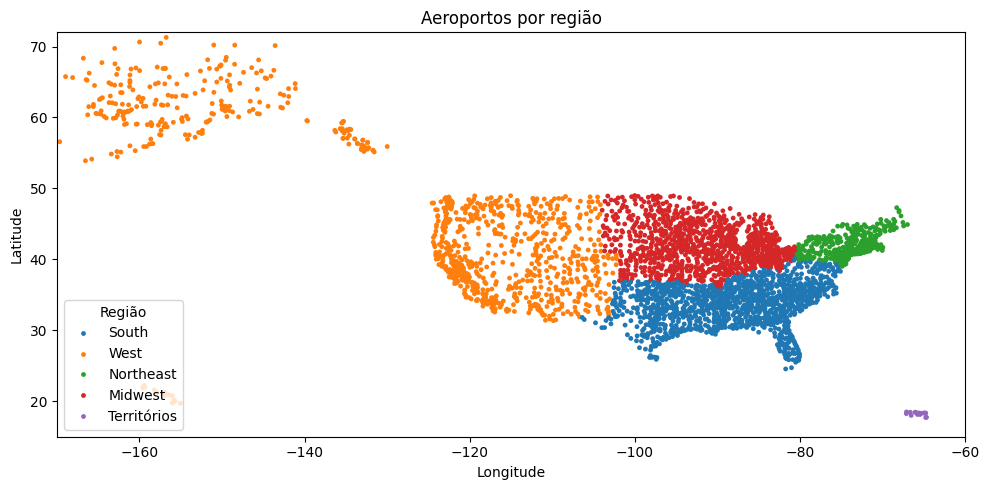

In [6]:
# Visualização da distribuição geográfica dos aeroportos por região
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_modelo, x="longitude", y="latitude", hue="regiao", s=12, linewidth=0)
plt.xlim(-170, -60)   # recorte visual, não afeta os dados dos modelos
plt.ylim(15, 72)
plt.title("Aeroportos por região")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Região", loc="lower left")
plt.tight_layout()
plt.show()

## 5. Função auxiliar e modelo de referência: Árvore de Decisão

Para evitar repetir o mesmo código em cada modelo, foi criada uma função que treina o modelo, mede o tempo de treinamento, faz as predições no conjunto de teste, calcula a acurácia e o F1-score macro e guarda tudo em um dicionário, que será usado depois na comparação final.

O modelo de referência é uma única árvore de decisão. Como as fronteiras entre regiões são irregulares no plano de latitude e longitude, foi usada uma profundidade máxima de 8, suficiente para capturar essas divisões sem deixar a árvore crescer sem limite.

In [7]:
resultados = {}

def treinar_e_avaliar(nome, modelo):
    """Treina o modelo, avalia no conjunto de teste e guarda os resultados."""
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo = time.perf_counter() - inicio

    pred = modelo.predict(X_test)
    acuracia = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")

    resultados[nome] = {
        "modelo": modelo,
        "pred": pred,
        "acuracia": acuracia,
        "f1_macro": f1,
        "tempo": tempo,
    }

    print(f"Acurácia ({nome}): {acuracia:.4f}")
    print(f"F1-score macro ({nome}): {f1:.4f}")
    print(f"Tempo de treinamento: {tempo:.2f} s")
    print("\nRelatório de classificação:")
    print(classification_report(y_test, pred, zero_division=0))


tree_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=2,
    random_state=RANDOM_STATE
)

treinar_e_avaliar("Árvore de Decisão", tree_model)

Acurácia (Árvore de Decisão): 0.9857
F1-score macro (Árvore de Decisão): 0.9888
Tempo de treinamento: 0.02 s

Relatório de classificação:
              precision    recall  f1-score   support

     Midwest       0.97      0.98      0.98       233
   Northeast       0.98      1.00      0.99        79
       South       0.99      0.98      0.98       280
 Territórios       1.00      1.00      1.00         5
        West       1.00      0.99      1.00       243

    accuracy                           0.99       840
   macro avg       0.99      0.99      0.99       840
weighted avg       0.99      0.99      0.99       840



## 6. Bagging

O `BaggingClassifier` é configurado com árvores de decisão idênticas à do modelo de referência como estimadores-base. O parâmetro `n_estimators=100` define a quantidade de árvores do conjunto. Com `bootstrap=True` e `max_samples=0.8`, cada estimador recebe uma amostra com reposição correspondente a 80% do tamanho do conjunto de treino. O parâmetro `max_features=1.0` faz com que cada estimador considere todas as variáveis disponíveis, o que é adequado aqui, já que existem apenas duas, e `random_state=42` permite reproduzir os resultados.

No Bagging as árvores são independentes entre si, por isso o treinamento pode ser paralelizado (`n_jobs=-1`). Árvores relativamente profundas, que têm baixo viés e alta variância, são boas candidatas para esse método, pois a média das previsões reduz justamente a variância.

In [8]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=2,
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

treinar_e_avaliar("Bagging", bagging_model)

Acurácia (Bagging): 0.9869
F1-score macro (Bagging): 0.9895
Tempo de treinamento: 7.50 s

Relatório de classificação:
              precision    recall  f1-score   support

     Midwest       0.97      0.99      0.98       233
   Northeast       0.98      1.00      0.99        79
       South       0.99      0.98      0.99       280
 Territórios       1.00      1.00      1.00         5
        West       1.00      0.99      0.99       243

    accuracy                           0.99       840
   macro avg       0.99      0.99      0.99       840
weighted avg       0.99      0.99      0.99       840



## 7. Boosting

O Boosting é implementado com o `GradientBoostingClassifier`. Diferentemente do Bagging, as árvores são construídas em sequência, e cada nova árvore é treinada para corrigir os erros residuais do conjunto formado pelas anteriores. Por isso o treinamento não pode ser paralelizado.

Foram usados `n_estimators=200` árvores, `learning_rate=0.1`, que controla o quanto cada árvore contribui para a correção, e `max_depth=3`. A escolha de árvores rasas é intencional: no Boosting os estimadores devem ser *weak learners*, isto é, modelos simples e com alto viés, que vão sendo combinados até formar um preditor forte. Esse é o oposto do que se faz no Bagging, que prefere árvores profundas.

In [9]:
boosting_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

treinar_e_avaliar("Boosting", boosting_model)

Acurácia (Boosting): 0.9893
F1-score macro (Boosting): 0.9920
Tempo de treinamento: 12.10 s

Relatório de classificação:
              precision    recall  f1-score   support

     Midwest       0.98      0.98      0.98       233
   Northeast       1.00      0.99      0.99        79
       South       0.98      0.99      0.99       280
 Territórios       1.00      1.00      1.00         5
        West       1.00      1.00      1.00       243

    accuracy                           0.99       840
   macro avg       0.99      0.99      0.99       840
weighted avg       0.99      0.99      0.99       840



## 8. Stacking

No Stacking são combinados modelos de naturezas diferentes. Os estimadores-base escolhidos foram uma Random Forest, uma SVM com kernel RBF e um KNN, que representam abordagens bem distintas: conjunto de árvores, fronteira de margem máxima e vizinhança. A SVM e o KNN dependem de distâncias, então recebem os dados padronizados por meio do `StandardScaler` dentro de um `Pipeline`.

O classificador final, ou meta-aprendiz, é uma Regressão Logística, que aprende a combinar as probabilidades previstas pelos três estimadores-base. Com `cv=5`, o meta-aprendiz é treinado com previsões obtidas por validação cruzada, o que evita que ele aprenda a partir de previsões feitas sobre dados que os estimadores-base já viram durante o treino.

In [10]:
base_estimators = [
    ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    ("svm", make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE))),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
]

stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
    n_jobs=-1
)

treinar_e_avaliar("Stacking", stacking_model)

Acurácia (Stacking): 0.9881
F1-score macro (Stacking): 0.9420
Tempo de treinamento: 5.17 s

Relatório de classificação:
              precision    recall  f1-score   support

     Midwest       0.98      0.99      0.99       233
   Northeast       0.99      1.00      0.99        79
       South       0.99      0.99      0.99       280
 Territórios       1.00      0.60      0.75         5
        West       0.99      1.00      0.99       243

    accuracy                           0.99       840
   macro avg       0.99      0.91      0.94       840
weighted avg       0.99      0.99      0.99       840



## 9. Avaliação e comparação dos resultados

A **acurácia** representa a proporção total de previsões corretas. O **F1-score macro** calcula o F1 de cada classe e depois faz a média sem ponderar pela quantidade de exemplos de cada uma. Essa segunda métrica é útil neste conjunto porque as regiões não aparecem na mesma proporção: há muito mais aeroportos no Alasca e no restante do Oeste, por exemplo, do que nos territórios. Também é registrado o tempo de treinamento, já que os métodos têm custos computacionais bem diferentes.

A comparação abaixo utiliza exatamente o mesmo conjunto de teste para todos os modelos.

,Modelo,Acurácia,F1-score macro,Tempo de treino (s)
0,Árvore de Decisão,0.9857,0.9888,0.02
1,Bagging,0.9869,0.9895,7.50
2,Boosting,0.9893,0.9920,12.10
3,Stacking,0.9881,0.9420,5.17


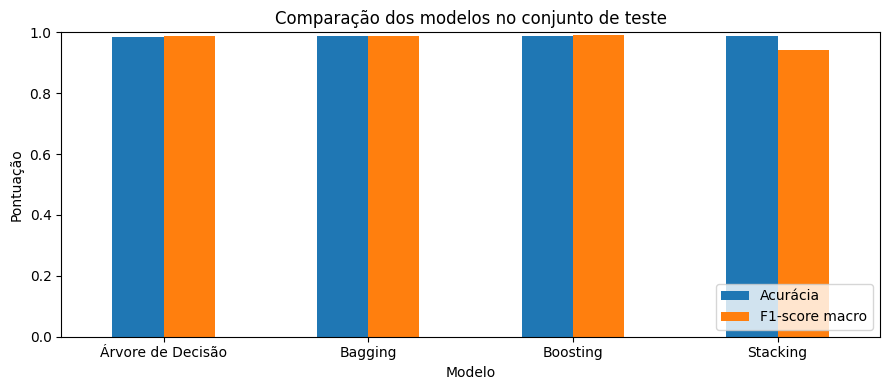

In [11]:
tabela = pd.DataFrame({
    "Modelo": list(resultados.keys()),
    "Acurácia": [r["acuracia"] for r in resultados.values()],
    "F1-score macro": [r["f1_macro"] for r in resultados.values()],
    "Tempo de treino (s)": [r["tempo"] for r in resultados.values()],
})

display(tabela.style.format({
    "Acurácia": "{:.4f}",
    "F1-score macro": "{:.4f}",
    "Tempo de treino (s)": "{:.2f}"
}))

ax = tabela.set_index("Modelo")[["Acurácia", "F1-score macro"]].plot(
    kind="bar",
    figsize=(9, 4),
    ylim=(0, 1),
    rot=0
)
ax.set_title("Comparação dos modelos no conjunto de teste")
ax.set_ylabel("Pontuação")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

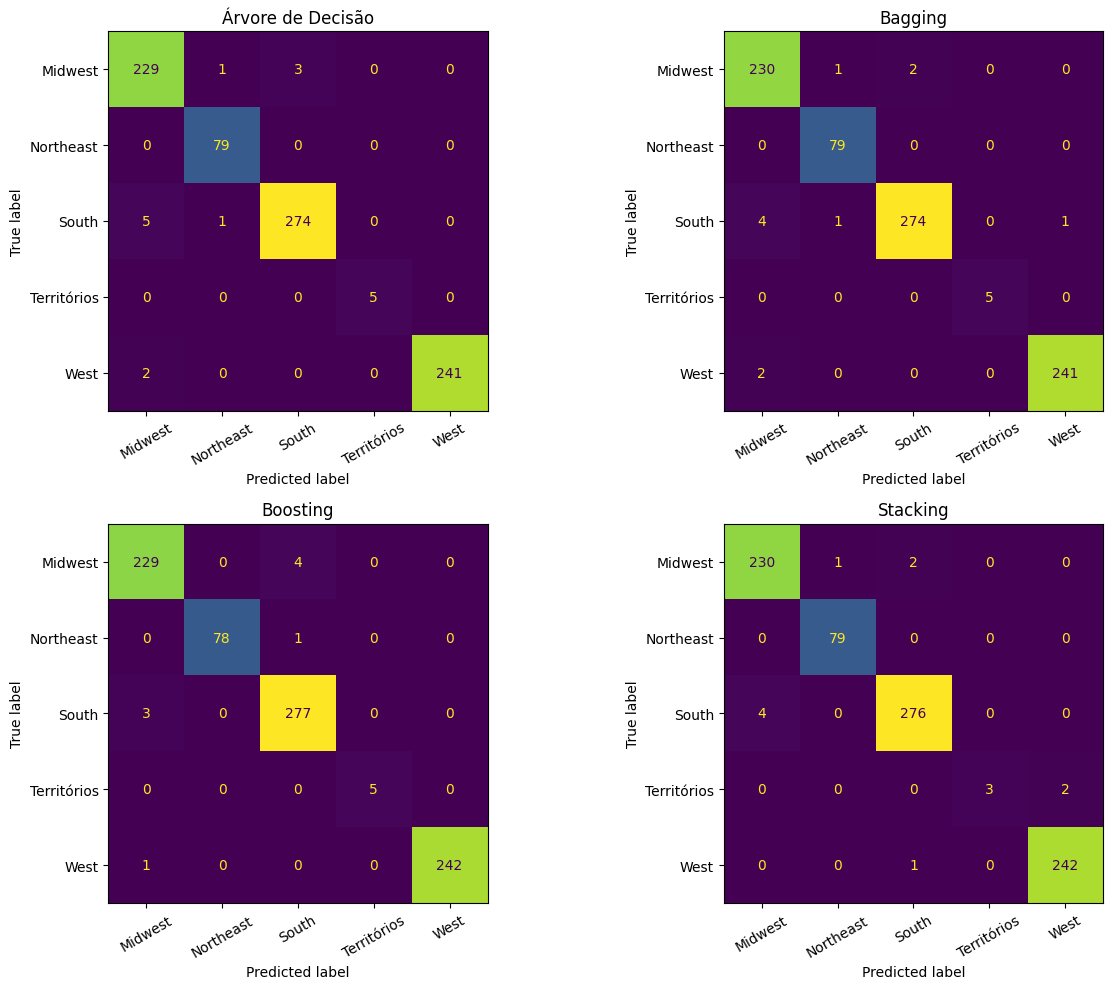

In [12]:
# Matrizes de confusão de todos os modelos
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (nome, r) in zip(axes.ravel(), resultados.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, r["pred"], ax=ax, xticks_rotation=30, colorbar=False
    )
    ax.set_title(nome)

plt.tight_layout()
plt.show()

In [13]:
# Desempenho por região (recall): mostra em quais classes cada modelo mais erra
classes = sorted(y_test.unique())

recall_por_classe = pd.DataFrame(index=pd.Index(classes, name="regiao"))
for nome, r in resultados.items():
    rep = classification_report(y_test, r["pred"], output_dict=True, zero_division=0)
    recall_por_classe[nome] = [rep[c]["recall"] for c in classes]

display(recall_por_classe.style.format("{:.4f}"))

# Resumo automático dos resultados
referencia = "Árvore de Decisão"
melhor = tabela.loc[tabela["F1-score macro"].idxmax(), "Modelo"]

print(f"\nMelhor F1-score macro: {melhor} ({resultados[melhor]['f1_macro']:.4f})")
print(f"Menor tempo de treino: {tabela.loc[tabela['Tempo de treino (s)'].idxmin(), 'Modelo']}")
print(f"Maior tempo de treino: {tabela.loc[tabela['Tempo de treino (s)'].idxmax(), 'Modelo']}")

print(f"\nDiferença em relação à {referencia} (positivo significa melhor que a árvore):")
for nome in ["Bagging", "Boosting", "Stacking"]:
    d_acc = resultados[nome]["acuracia"] - resultados[referencia]["acuracia"]
    d_f1 = resultados[nome]["f1_macro"] - resultados[referencia]["f1_macro"]
    print(f"  {nome}: acurácia {d_acc:+.4f} | F1-score macro {d_f1:+.4f}")

print(f"\nClasse com menor recall no melhor modelo ({melhor}): "
      f"{recall_por_classe[melhor].idxmin()} ({recall_por_classe[melhor].min():.4f})")

# Confusão mais frequente do melhor modelo (maior valor fora da diagonal)
cm = confusion_matrix(y_test, resultados[melhor]["pred"], labels=classes)
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(cm.argmax(), cm.shape)
print(f"Confusão mais frequente no melhor modelo: {classes[i]} previsto como {classes[j]} ({cm[i, j]} casos)")

,Árvore de Decisão,Bagging,Boosting,Stacking
regiao,,,,
Midwest,0.9828,0.9871,0.9828,0.9871
Northeast,1.0000,1.0000,0.9873,1.0000
South,0.9786,0.9786,0.9893,0.9857
Territórios,1.0000,1.0000,1.0000,0.6000
West,0.9918,0.9918,0.9959,0.9959



Melhor F1-score macro: Boosting (0.9920)
Menor tempo de treino: Árvore de Decisão
Maior tempo de treino: Boosting

Diferença em relação à Árvore de Decisão (positivo significa melhor que a árvore):
  Bagging: acurácia +0.0012 | F1-score macro +0.0008
  Boosting: acurácia +0.0036 | F1-score macro +0.0033
  Stacking: acurácia +0.0024 | F1-score macro -0.0467

Classe com menor recall no melhor modelo (Boosting): Midwest (0.9828)
Confusão mais frequente no melhor modelo: Midwest previsto como South (4 casos)


## 10. Análise dos resultados

A análise deve ser feita a partir da tabela comparativa, dos relatórios de classificação, das matrizes de confusão e da tabela de recall por região. Vale observar se os três ensembles superaram a árvore de decisão individual, se a ordem entre os modelos é a mesma na acurácia e no F1-score macro, em quais regiões ocorrem mais erros e quanto cada método custou em tempo de treinamento. A última célula de código acima resume esses números, incluindo o melhor modelo, a região de pior desempenho e a confusão mais frequente.

Do ponto de vista geográfico, é esperado que os erros se concentrem nas fronteiras entre regiões vizinhas, onde aeroportos com latitude e longitude muito próximas pertencem a regiões diferentes, e nas classes com poucos exemplos, como os territórios. Em relação aos métodos, o Bagging reduz a variância ao combinar árvores profundas treinadas em amostras diferentes, o Boosting reduz o viés ao corrigir sequencialmente os erros de árvores rasas, e o Stacking tenta aproveitar pontos fortes complementares de modelos distintos. Como o problema depende de apenas duas variáveis e de fronteiras irregulares, é possível que as diferenças entre os modelos sejam pequenas, e não há garantia de que um ensemble supere os demais em qualquer conjunto de dados. Por isso a conclusão deve se basear nos valores efetivamente obtidos ao executar as células.

## 11. Conclusão

Neste laboratório foram implementados três tipos de ensemble com Scikit-Learn, o Bagging, o Boosting e o Stacking, utilizando o conjunto Airports do `vega_datasets` para prever a região dos Estados Unidos em que um aeroporto se localiza a partir de sua latitude e longitude. Todos os modelos foram treinados e avaliados com a mesma divisão de treino e teste e comparados entre si e com uma árvore de decisão individual.

A atividade percorre o fluxo completo de um experimento de aprendizado de máquina: seleção dos dados, construção da variável-alvo, definição das variáveis preditoras, divisão treino/teste, construção dos modelos, treinamento e avaliação por métricas de classificação. Também permitiu contrastar as três estratégias de combinação: estimadores independentes treinados em amostras bootstrap, estimadores sequenciais que corrigem os erros anteriores e estimadores heterogêneos combinados por um meta-aprendiz.

## 12. Referências

SCIKIT-LEARN. **Ensemble methods**. Disponível em: https://scikit-learn.org/stable/modules/ensemble.html.

SCIKIT-LEARN. **BaggingClassifier**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html.

SCIKIT-LEARN. **GradientBoostingClassifier**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html.

SCIKIT-LEARN. **StackingClassifier**. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html.

VEGA DATASETS. **Airports dataset**. Disponível em: https://github.com/vega/vega-datasets.

GEEKSFORGEEKS. **Bagging vs Boosting vs Stacking in Machine Learning**. Disponível em: https://www.geeksforgeeks.org/machine-learning/bagging-vs-boosting-vs-stacking/.

GEEKSFORGEEKS. **Boosting in Machine Learning**. Disponível em: https://www.geeksforgeeks.org/machine-learning/boosting-in-machine-learning/.